In [5]:
!pip install pandas numpy matplotlib seaborn scikit-learn shap



   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]




[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')
pd.set_option('display.max_columns', 50)

In [2]:
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()
print("\nNulls per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df['Attrition'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [4]:
drop_cols = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df_clean = df.drop(columns=drop_cols)
df_clean.shape

(1470, 31)

In [5]:
df_clean['Attrition_Flag'] = df_clean['Attrition'].map({'Yes': 1, 'No': 0})
df_clean[['Attrition', 'Attrition_Flag']].value_counts()

Attrition  Attrition_Flag
No         0                 1233
Yes        1                  237
Name: count, dtype: int64

In [6]:
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']
num_cols = df_clean.select_dtypes(include='number').columns.tolist()
num_cols = [c for c in num_cols if c != 'Attrition_Flag']

print("Categorical:", cat_cols)
print("\nNumerical:", num_cols)

Categorical: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [7]:
df_clean['SalaryBand'] = pd.cut(
    df_clean['MonthlyIncome'],
    bins=[0, 3000, 6000, 10000, 15000, 25000],
    labels=['<3K', '3K-6K', '6K-10K', '10K-15K', '15K+']
)
df_clean[['MonthlyIncome', 'SalaryBand']].head()

,MonthlyIncome,SalaryBand
0,5993,3K-6K
1,5130,3K-6K
2,2090,<3K
3,2909,<3K
4,3468,3K-6K


EDA

Overall attrition rate: 16.12%


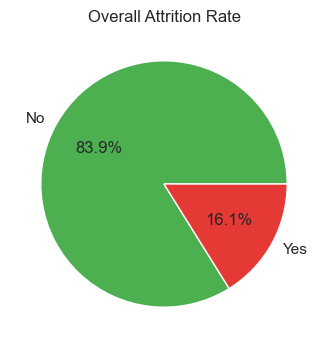

In [8]:
attrition_rate = df_clean['Attrition_Flag'].mean() * 100
print(f"Overall attrition rate: {attrition_rate:.2f}%")

plt.figure(figsize=(4,4))
df_clean['Attrition'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#4CAF50','#E53935'])
plt.title('Overall Attrition Rate')
plt.ylabel('')
plt.savefig('chart_overall_attrition.png', dpi=150, bbox_inches='tight')
plt.show()

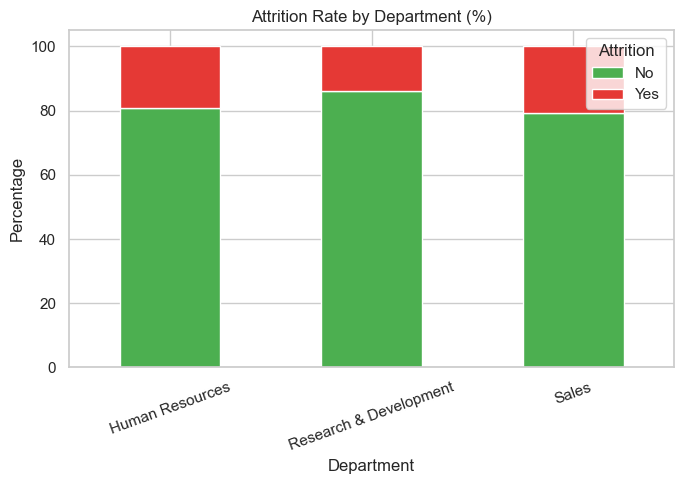

In [9]:
plt.figure(figsize=(7,5))
dept_attr = pd.crosstab(df_clean['Department'], df_clean['Attrition'], normalize='index') * 100
dept_attr.plot(kind='bar', stacked=True, color=['#4CAF50','#E53935'], ax=plt.gca())
plt.title('Attrition Rate by Department (%)')
plt.ylabel('Percentage')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('chart_dept_attrition.png', dpi=150, bbox_inches='tight')
plt.show()

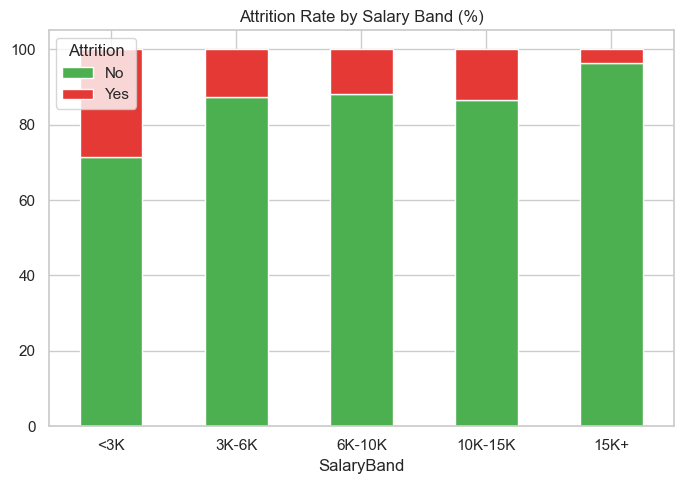

In [10]:
plt.figure(figsize=(7,5))
salary_attr = pd.crosstab(df_clean['SalaryBand'], df_clean['Attrition'], normalize='index') * 100
salary_attr.plot(kind='bar', stacked=True, color=['#4CAF50','#E53935'], ax=plt.gca())
plt.title('Attrition Rate by Salary Band (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('chart_salary_attrition.png', dpi=150, bbox_inches='tight')
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20384\3355739040.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y='YearsSinceLastPromotion', data=df_clean, palette=['#4CAF50','#E53935'])


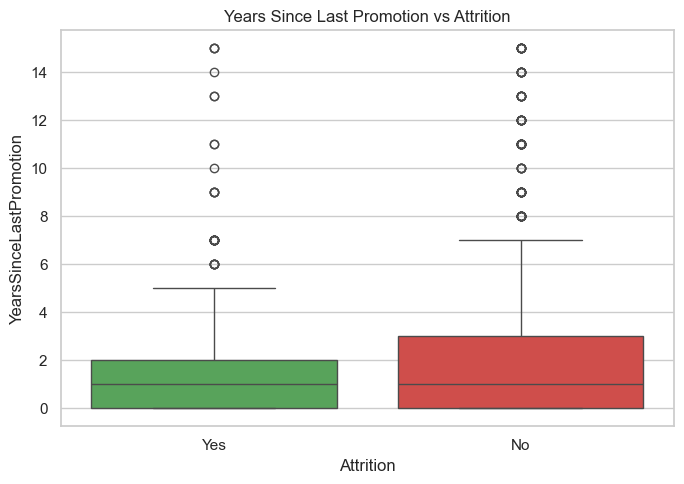

In [11]:
plt.figure(figsize=(7,5))
sns.boxplot(x='Attrition', y='YearsSinceLastPromotion', data=df_clean, palette=['#4CAF50','#E53935'])
plt.title('Years Since Last Promotion vs Attrition')
plt.tight_layout()
plt.savefig('chart_promotion_attrition.png', dpi=150, bbox_inches='tight')
plt.show()

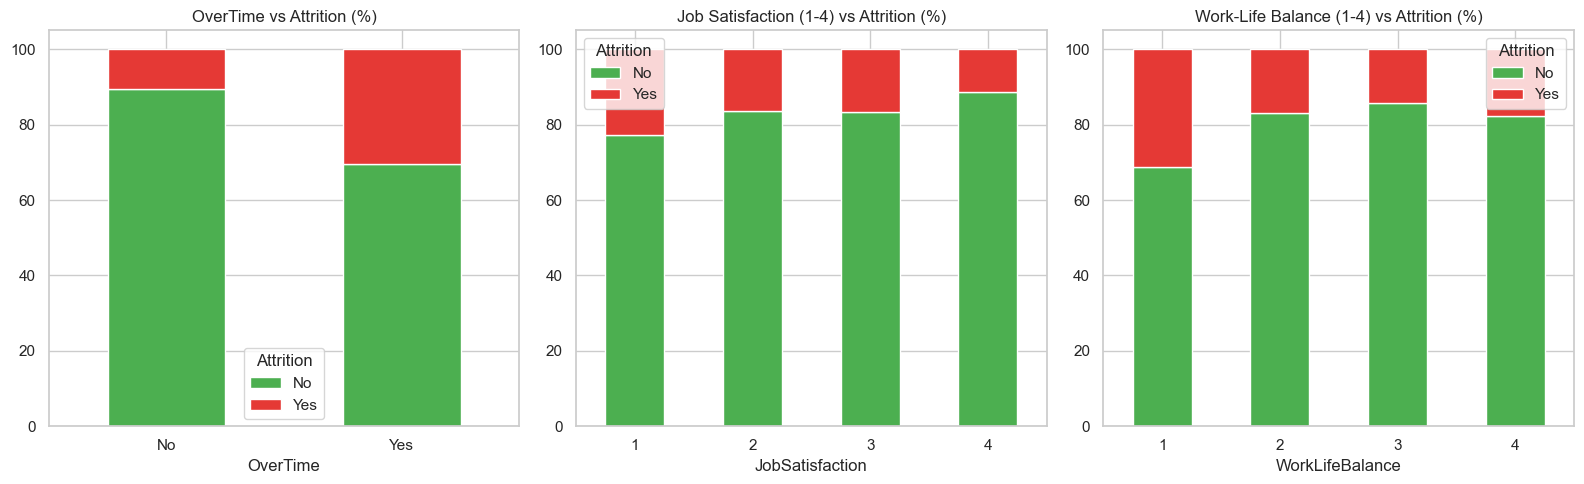

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))

ot = pd.crosstab(df_clean['OverTime'], df_clean['Attrition'], normalize='index') * 100
ot.plot(kind='bar', stacked=True, color=['#4CAF50','#E53935'], ax=axes[0])
axes[0].set_title('OverTime vs Attrition (%)')
axes[0].tick_params(axis='x', rotation=0)

js = pd.crosstab(df_clean['JobSatisfaction'], df_clean['Attrition'], normalize='index') * 100
js.plot(kind='bar', stacked=True, color=['#4CAF50','#E53935'], ax=axes[1])
axes[1].set_title('Job Satisfaction (1-4) vs Attrition (%)')
axes[1].tick_params(axis='x', rotation=0)

wlb = pd.crosstab(df_clean['WorkLifeBalance'], df_clean['Attrition'], normalize='index') * 100
wlb.plot(kind='bar', stacked=True, color=['#4CAF50','#E53935'], ax=axes[2])
axes[2].set_title('Work-Life Balance (1-4) vs Attrition (%)')
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('chart_satisfaction_factors.png', dpi=150, bbox_inches='tight')
plt.show()

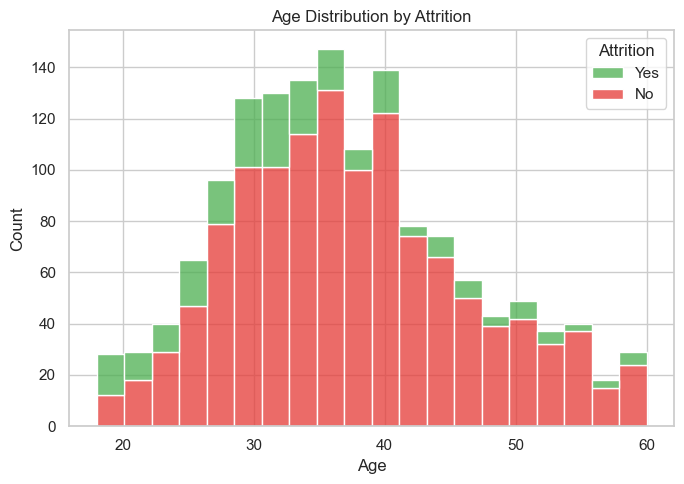

In [13]:
plt.figure(figsize=(7,5))
sns.histplot(data=df_clean, x='Age', hue='Attrition', multiple='stack', palette=['#4CAF50','#E53935'], bins=20)
plt.title('Age Distribution by Attrition')
plt.tight_layout()
plt.savefig('chart_age_attrition.png', dpi=150, bbox_inches='tight')
plt.show()

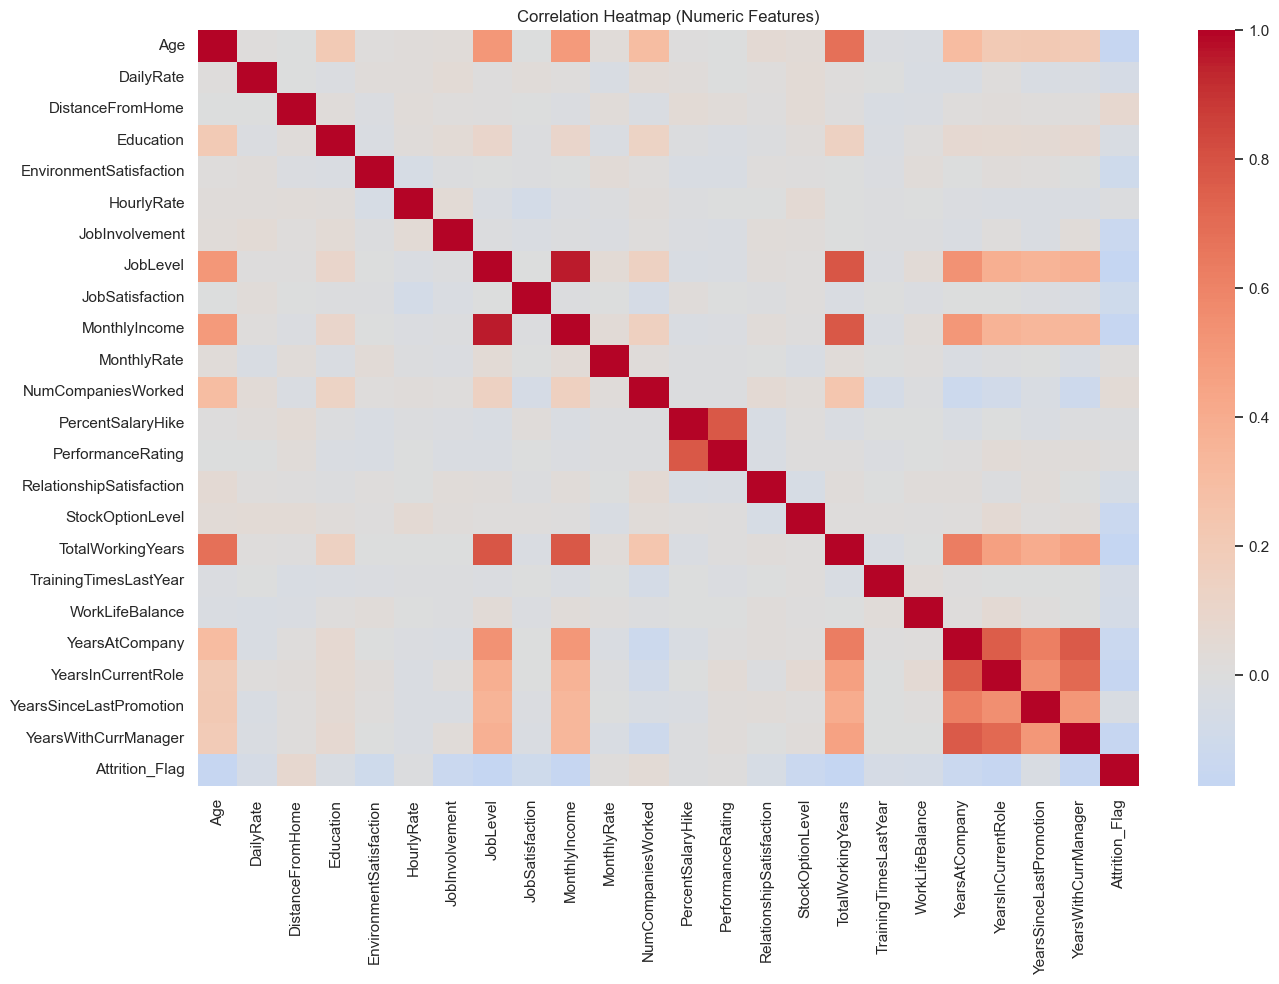

Attrition_Flag              1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
Name: Attrition_Flag, dtype: float64


In [14]:
plt.figure(figsize=(14,10))
corr = df_clean[num_cols + ['Attrition_Flag']].corr()
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.savefig('chart_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print(corr['Attrition_Flag'].sort_values(ascending=False))

In [15]:
df_clean.to_csv('HR_Attrition_Cleaned.csv', index=False)
print("Saved!")

Saved!


In [16]:
target = df_clean['Attrition_Flag']
features = df_clean.drop(columns=['Attrition', 'Attrition_Flag', 'SalaryBand'])
features.shape

(1470, 30)

In [17]:
cat_cols_features = features.select_dtypes(include='object').columns.tolist()
print("Categorical columns to encode:", cat_cols_features)

features_encoded = pd.get_dummies(features, columns=cat_cols_features, drop_first=True)
features_encoded.shape

Categorical columns to encode: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


(1470, 44)

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features_encoded, target,
    test_size=0.2, random_state=42, stratify=target
)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(1176, 44) (294, 44)
Attrition_Flag
0    0.838435
1    0.161565
Name: proportion, dtype: float64
Attrition_Flag
0    0.840136
1    0.159864
Name: proportion, dtype: float64


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)

(1176, 44) (294, 44)


In [20]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000, random_state=42)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.8605442176870748

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294


Confusion Matrix:
[[237  10]
 [ 31  16]]


In [22]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [23]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.8333333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91       247
           1       0.44      0.17      0.25        47

    accuracy                           0.83       294
   macro avg       0.65      0.56      0.58       294
weighted avg       0.79      0.83      0.80       294


Confusion Matrix:
[[237  10]
 [ 39   8]]


In [24]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.8333333333333334

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91       247
           1       0.42      0.11      0.17        47

    accuracy                           0.83       294
   macro avg       0.63      0.54      0.54       294
weighted avg       0.78      0.83      0.79       294


Confusion Matrix:
[[240   7]
 [ 42   5]]


In [26]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_dt,
        accuracy_rf
    ],
    "Attrition Precision": [
        0.62,
        0.44,
        0.42
    ],
    "Attrition Recall": [
        0.34,
        0.17,
        0.11
    ],
    "Attrition F1-Score": [
        0.44,
        0.25,
        0.17
    ]
})

model_comparison

,Model,Accuracy,Attrition Precision,Attrition Recall,Attrition F1-Score
0,Logistic Regression,0.860544,0.62,0.34,0.44
1,Decision Tree,0.833333,0.44,0.17,0.25
2,Random Forest,0.833333,0.42,0.11,0.17


In [27]:
!pip install shap


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [29]:
explainer = shap.LinearExplainer(
    logistic_model,
    X_train_scaled
)

shap_values = explainer(X_test_scaled)

print("SHAP values generated successfully!")

Background dataset has 1176 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1176 when initializing the masker.


SHAP values generated successfully!


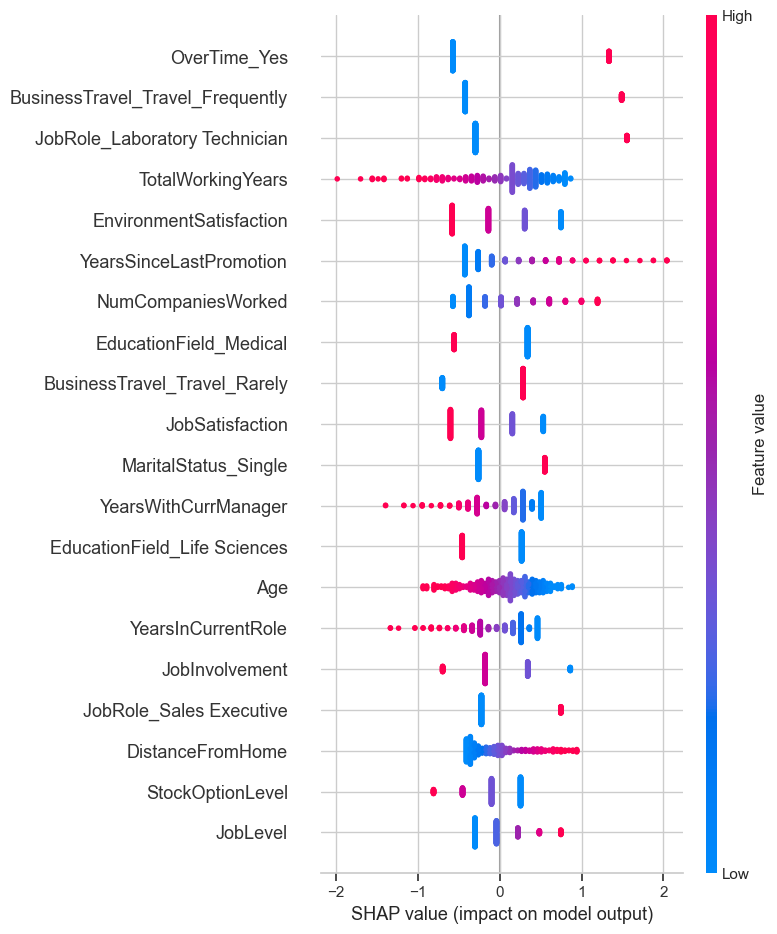

In [30]:
shap.summary_plot(
    shap_values.values,
    X_test_scaled,
    feature_names=features_encoded.columns
)

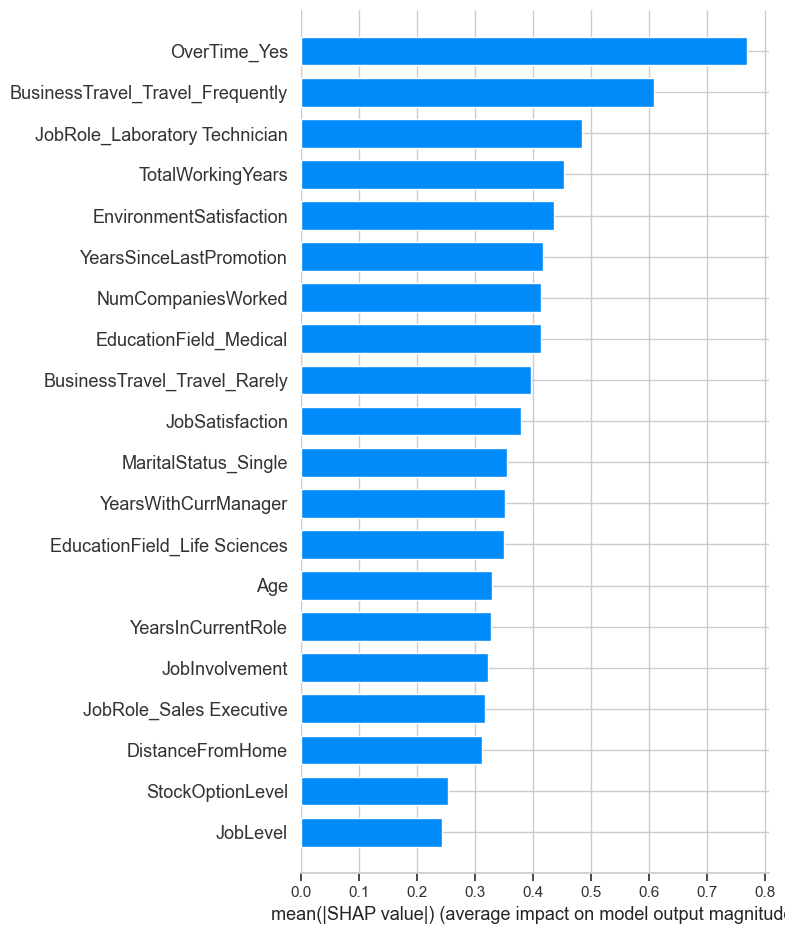

In [31]:
shap.summary_plot(
    shap_values.values,
    X_test_scaled,
    feature_names=features_encoded.columns,
    plot_type="bar"
)

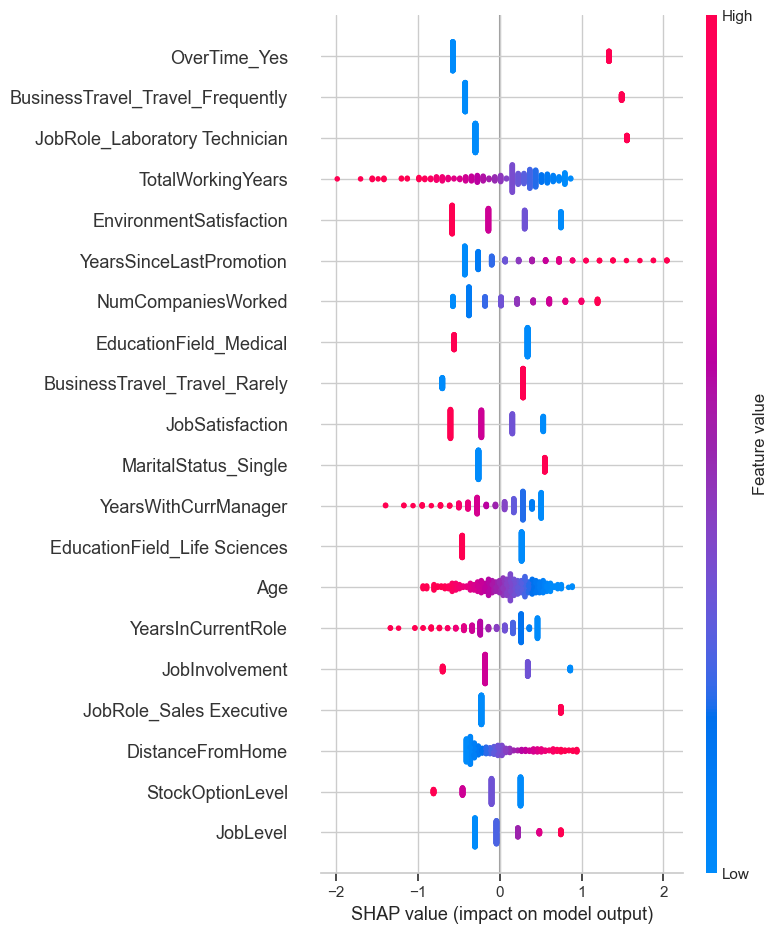

In [32]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values.values,
    X_test_scaled,
    feature_names=features_encoded.columns,
    show=False
)

plt.savefig("shap_summary_plot.png", bbox_inches="tight", dpi=300)
plt.show()

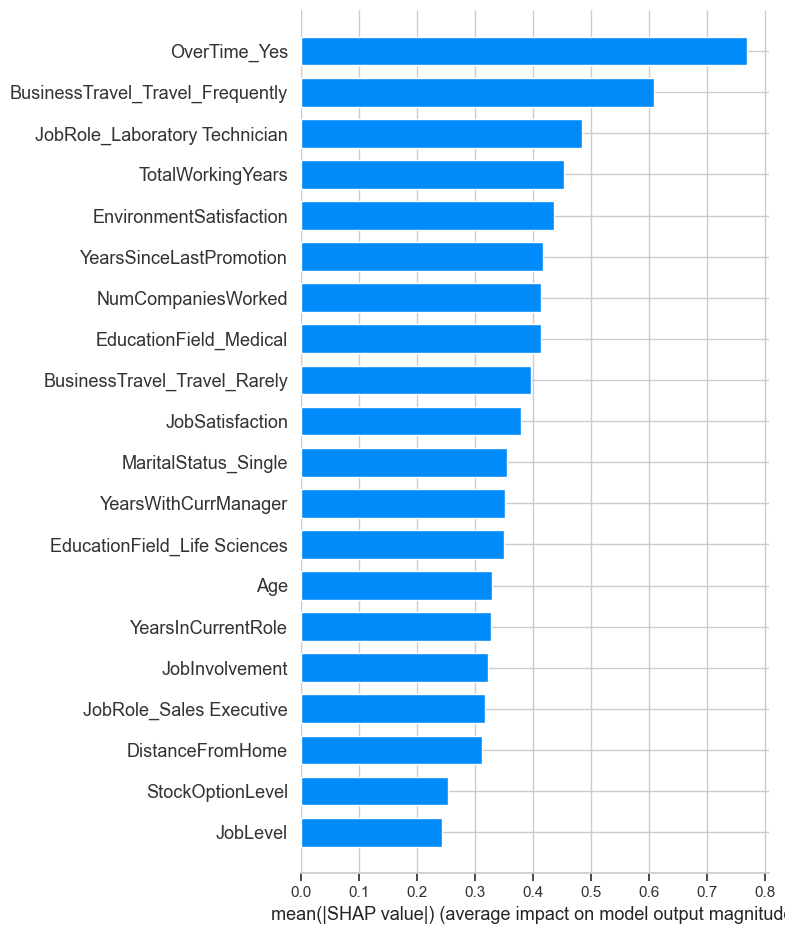

In [33]:
shap.summary_plot(
    shap_values.values,
    X_test_scaled,
    feature_names=features_encoded.columns,
    plot_type="bar",
    show=False
)

plt.savefig("shap_bar_plot.png", bbox_inches="tight", dpi=300)
plt.show()

In [34]:
powerbi_df = df_clean.copy()

powerbi_df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Flag,SalaryBand
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,1,3K-6K
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,0,3K-6K
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,1,<3K
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,0,<3K
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,0,3K-6K


In [35]:
powerbi_df.shape

(1470, 33)

In [36]:
powerbi_df.columns.tolist()

['Age',
 'Attrition',
 'BusinessTravel',
 'DailyRate',
 'Department',
 'DistanceFromHome',
 'Education',
 'EducationField',
 'EnvironmentSatisfaction',
 'Gender',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'OverTime',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Attrition_Flag',
 'SalaryBand']

In [37]:
powerbi_df.to_csv("HR_Analytics_PowerBI.csv", index=False)

print("Power BI dataset saved successfully!")

Power BI dataset saved successfully!
